# Data Cleaning & Reporting Automation

## Project Overview
This project automates data cleaning and reporting workflows using Python.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Objective
To clean raw data, handle missing values, remove duplicates, generate business reports, and visualize important insights.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
folder = "Retail_Sales_Analysis"
os.makedirs(folder, exist_ok=True)

print("Project folder created successfully!")

Project folder created successfully!


In [7]:
# Generate the raw dataset
messy_data = {
    "OrderID": [1001, 1002, 1003, 1004, 1005,
                1006, 1007, 1008, 1009, 1010,
                1011, 1012, 1013, 1014, 1015],

    "CustomerID": [101, 102, np.nan, 104, 101,
                   105, 106, 107, 108, 109,
                   110, 111, 112, 113, 114],

    "Date": ["2026-01-01", "2026-01-05", "2026-01-10",
             " 2026-01-12 ", "2026-01-15",
             "2026-02-01", "2026-02-05", "2026-02-10",
             "2026-02-15", "2026-03-01",
             "2026-03-05", "2026-03-10",
             "2026-03-15", "missing_date", "2026-03-20"],

    "Product_Category": [
        " electronics ", "Furniture", "Electronics",
        "Clothing", " electronics ", "CLOTHING",
        "Furniture", "Electronics", "Clothing",
        "Furniture", "Electronics", "Clothing",
        "Furniture", "Electronics", "Clothing"
    ],

    "Quantity": [2, np.nan, 1, 5, 2, 10, -3, 4,
                 3, 2, 6, 8, 4, 5, 3],

    "Price": ["$120.00", "$450.50", "$85.00",
              "$25.00", "$120.00", "$22.00",
              "$0.00", "$50.00", "$30.00",
              "$400.00", "$150.00", "$20.00",
              "$350.00", "$75.00", "$40.00"],

    "Region": ["South", "North", "East", "West",
               "South", "North", "East", "West",
               "South", "North", "East", "West",
               "South", "North", "East"]
}

df = pd.DataFrame(messy_data)

df.to_csv(os.path.join(folder, "raw_data.csv"), index=False)

print("Raw dataset created successfully!")

Raw dataset created successfully!


In [8]:
# Understand the dataset
print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(15, 7)

First 5 Records:


,OrderID,CustomerID,Date,Product_Category,Quantity,Price,Region
0,1001,101.0,2026-01-01,electronics,2.0,$120.00,South
1,1002,102.0,2026-01-05,Furniture,NaN,$450.50,North
2,1003,NaN,2026-01-10,Electronics,1.0,$85.00,East
3,1004,104.0,2026-01-12,Clothing,5.0,$25.00,West
4,1005,101.0,2026-01-15,electronics,2.0,$120.00,South



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   OrderID           15 non-null     int64  
 1   CustomerID        14 non-null     float64
 2   Date              15 non-null     object 
 3   Product_Category  15 non-null     object 
 4   Quantity          14 non-null     float64
 5   Price             15 non-null     object 
 6   Region            15 non-null     object 
dtypes: float64(2), int64(1), object(4)
memory usage: 972.0+ bytes

Statistical Summary:


,OrderID,CustomerID,Date,Product_Category,Quantity,Price,Region
count,15.000000,14.000000,15,15,14.000000,15,15
unique,NaN,NaN,15,5,NaN,14,4
top,NaN,NaN,2026-01-01,Furniture,NaN,$120.00,South
freq,NaN,NaN,1,4,NaN,2,4
mean,1008.000000,107.357143,NaN,NaN,3.714286,NaN,NaN
std,4.472136,4.378394,NaN,NaN,3.148347,NaN,NaN
min,1001.000000,101.000000,NaN,NaN,-3.000000,NaN,NaN
25%,1004.500000,104.250000,NaN,NaN,2.000000,NaN,NaN
50%,1008.000000,107.500000,NaN,NaN,3.500000,NaN,NaN
75%,1011.500000,110.750000,NaN,NaN,5.000000,NaN,NaN



Missing Values:
OrderID             0
CustomerID          1
Date                0
Product_Category    0
Quantity            1
Price               0
Region              0
dtype: int64


In [9]:
#Clean the data
original_rows = len(df)

# Standardize text
df["Product_Category"] = (
    df["Product_Category"].str.strip().str.title()
)

df["Region"] = df["Region"].str.strip().str.title()

# Convert price into numeric format
df["Price"] = (
    df["Price"].replace(r"[\$,]", "", regex=True).astype(float)
)

# Convert date into datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove duplicates
duplicates = df.duplicated().sum()
df = df.drop_duplicates()

# Fill missing quantity
df["Quantity"] = df["Quantity"].fillna(
    df.groupby("Product_Category")["Quantity"].transform("median")
)

# Count missing critical records
missing_critical = df[
    df["CustomerID"].isna() | df["Date"].isna()
].shape[0]

# Remove missing critical records
df = df.dropna(subset=["CustomerID", "Date"])

# Count invalid transactions
invalid_rows = df[
    (df["Price"] <= 0) | (df["Quantity"] <= 0)
].shape[0]

# Remove invalid transactions
df = df[(df["Price"] > 0) & (df["Quantity"] > 0)]

# Convert data types
df["CustomerID"] = df["CustomerID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)

print("Data cleaning completed successfully!")
display(df)

Data cleaning completed successfully!


,OrderID,CustomerID,Date,Product_Category,Quantity,Price,Region
0,1001,101,2026-01-01,Electronics,2,120.0,South
1,1002,102,2026-01-05,Furniture,2,450.5,North
4,1005,101,2026-01-15,Electronics,2,120.0,South
5,1006,105,2026-02-01,Clothing,10,22.0,North
7,1008,107,2026-02-10,Electronics,4,50.0,West
8,1009,108,2026-02-15,Clothing,3,30.0,South
9,1010,109,2026-03-01,Furniture,2,400.0,North
10,1011,110,2026-03-05,Electronics,6,150.0,East
11,1012,111,2026-03-10,Clothing,8,20.0,West
12,1013,112,2026-03-15,Furniture,4,350.0,South


In [10]:
#Generate the data quality report
quality_report = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Duplicate Rows",
        "Missing Critical Rows",
        "Invalid Transaction Rows",
        "Final Clean Rows",
        "Removed Rows"
    ],
    "Count": [
        original_rows,
        duplicates,
        missing_critical,
        invalid_rows,
        len(df),
        original_rows - len(df)
    ]
})

display(quality_report)

quality_report.to_csv(
    os.path.join(folder, "data_quality_report.csv"),
    index=False
)

print("Data quality report saved!")

,Metric,Count
0,Original Rows,15
1,Duplicate Rows,0
2,Missing Critical Rows,3
3,Invalid Transaction Rows,1
4,Final Clean Rows,11
5,Removed Rows,4


Data quality report saved!


In [11]:
#Feature Engineering
#Purpose: Create new columns to help with business analysis.
# Calculate total revenue
df["Total_Revenue"] = df["Quantity"] * df["Price"]

# Extract month, year and day
df["Month"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year
df["Day"] = df["Date"].dt.day_name()

print("New columns created successfully!")

display(df.head())

New columns created successfully!


,OrderID,CustomerID,Date,Product_Category,Quantity,Price,Region,Total_Revenue,Month,Year,Day
0,1001,101,2026-01-01,Electronics,2,120.0,South,240.0,January,2026,Thursday
1,1002,102,2026-01-05,Furniture,2,450.5,North,901.0,January,2026,Monday
4,1005,101,2026-01-15,Electronics,2,120.0,South,240.0,January,2026,Thursday
5,1006,105,2026-02-01,Clothing,10,22.0,North,220.0,February,2026,Sunday
7,1008,107,2026-02-10,Electronics,4,50.0,West,200.0,February,2026,Tuesday


In [12]:
#Calculate Business KPIs
total_revenue = df["Total_Revenue"].sum()

total_orders = df["OrderID"].nunique()

total_customers = df["CustomerID"].nunique()

total_units = df["Quantity"].sum()

average_order_value = total_revenue / total_orders

average_price = df["Price"].mean()

kpi_report = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Total Units Sold",
        "Average Order Value",
        "Average Product Price"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        total_units,
        average_order_value,
        average_price
    ]
})

display(kpi_report)

print("Business KPIs calculated successfully!")

,KPI,Value
0,Total Revenue,5271.000000
1,Total Orders,11.000000
2,Unique Customers,10.000000
3,Total Units Sold,46.000000
4,Average Order Value,479.181818
5,Average Product Price,159.318182


Business KPIs calculated successfully!


In [13]:
#Category-wise Analysis
category_summary = df.groupby("Product_Category").agg(
    Total_Revenue=("Total_Revenue", "sum"),
    Total_Units=("Quantity", "sum"),
    Total_Orders=("OrderID", "nunique"),
    Unique_Customers=("CustomerID", "nunique"),
    Average_Price=("Price", "mean")
).reset_index()

category_summary = category_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

display(category_summary)

category_summary.to_csv(
    os.path.join(folder, "category_summary.csv"),
    index=False
)

print("Category analysis completed!")

,Product_Category,Total_Revenue,Total_Units,Total_Orders,Unique_Customers,Average_Price
2,Furniture,3101.0,8,3,3,400.166667
1,Electronics,1580.0,14,4,3,110.000000
0,Clothing,590.0,24,4,4,28.000000


Category analysis completed!


In [14]:
#Region-wise Analysis
#Purpose: Understand sales performance in different regions.
region_summary = df.groupby("Region").agg(
    Total_Revenue=("Total_Revenue", "sum"),
    Total_Units=("Quantity", "sum"),
    Unique_Customers=("CustomerID", "nunique")
).reset_index()

region_summary = region_summary.sort_values(
    by="Total_Revenue",
    ascending=False
)

display(region_summary)

region_summary.to_csv(
    os.path.join(folder, "region_summary.csv"),
    index=False
)

print("Region analysis completed!")

,Region,Total_Revenue,Total_Units,Unique_Customers
2,South,1970.0,11,3
1,North,1921.0,14,3
0,East,1020.0,9,2
3,West,360.0,12,2


Region analysis completed!


In [15]:
#Monthly Sales Analysis
monthly_summary = df.groupby(
    df["Date"].dt.to_period("M")
).agg(
    Monthly_Revenue=("Total_Revenue", "sum"),
    Monthly_Units=("Quantity", "sum")
).reset_index()

monthly_summary["Date"] = monthly_summary["Date"].astype(str)

display(monthly_summary)

monthly_summary.to_csv(
    os.path.join(folder, "monthly_summary.csv"),
    index=False
)

print("Monthly analysis completed!")

,Date,Monthly_Revenue,Monthly_Units
0,2026-01,1381.0,6
1,2026-02,510.0,17
2,2026-03,3380.0,23


Monthly analysis completed!


In [16]:
#Automated Business Insights
best_category = category_summary.iloc[0]["Product_Category"]

best_region = region_summary.iloc[0]["Region"]

best_month = monthly_summary.loc[
    monthly_summary["Monthly_Revenue"].idxmax(), "Date"
]

print("=" * 45)
print("       BUSINESS INSIGHTS")
print("=" * 45)

print(f"Total Revenue: ${total_revenue:,.2f}")

print(f"Highest Revenue Category: {best_category}")

print(f"Highest Revenue Region: {best_region}")

print(f"Best Sales Month: {best_month}")

print(f"Total Customers: {total_customers}")

print(f"Total Units Sold: {total_units}")

print(f"Average Order Value: ${average_order_value:,.2f}")

       BUSINESS INSIGHTS
Total Revenue: $5,271.00
Highest Revenue Category: Furniture
Highest Revenue Region: South
Best Sales Month: 2026-03
Total Customers: 10
Total Units Sold: 46
Average Order Value: $479.18


## Create a complete visual dashboard poster

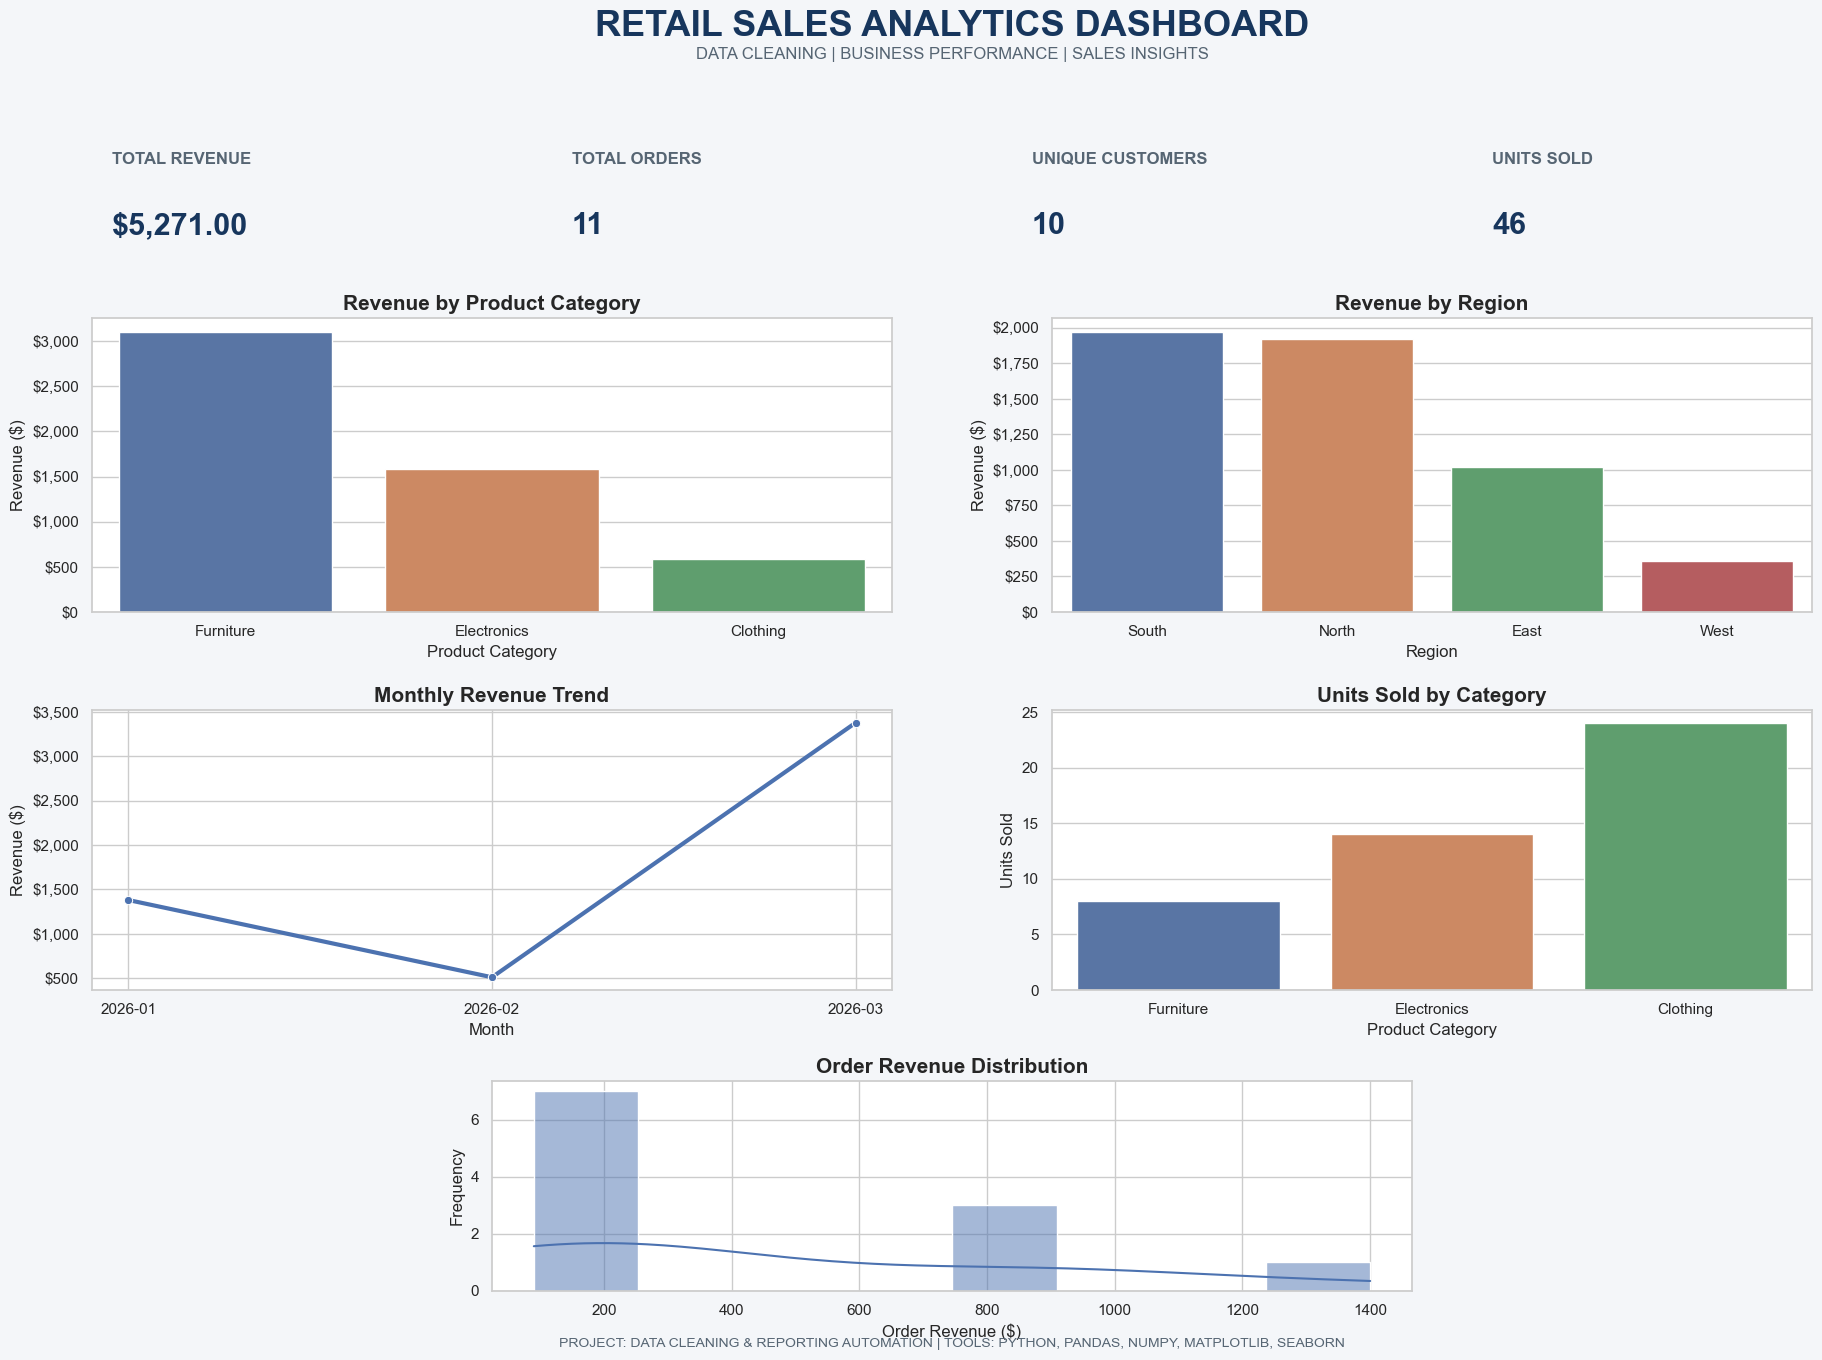

Professional dashboard poster created!
Saved at: Retail_Sales_Analysis\Retail_Sales_Dashboard_Poster.png


In [19]:

# ============================================================
# STEP 17: PROFESSIONAL RETAIL SALES DASHBOARD POSTER
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")

# Create dashboard canvas
fig = plt.figure(figsize=(20, 14), facecolor="#F4F6F9")

fig.suptitle(
    "RETAIL SALES ANALYTICS DASHBOARD",
    fontsize=26,
    fontweight="bold",
    color="#17365D",
    y=0.97
)

fig.text(
    0.5, 0.935,
    "DATA CLEANING | BUSINESS PERFORMANCE | SALES INSIGHTS",
    ha="center",
    fontsize=12,
    color="#566573"
)

# ============================================================
# KPI CARDS
# ============================================================

kpis = [
    ("TOTAL REVENUE", f"${total_revenue:,.2f}"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("UNIQUE CUSTOMERS", f"{total_customers:,}"),
    ("UNITS SOLD", f"{total_units:,}")
]

positions = [0.08, 0.31, 0.54, 0.77]

for (label, value), x in zip(kpis, positions):

    fig.text(
        x, 0.86, label,
        fontsize=12,
        fontweight="bold",
        color="#566573",
        ha="left"
    )

    fig.text(
        x, 0.81, value,
        fontsize=22,
        fontweight="bold",
        color="#17365D",
        ha="left"
    )

# ============================================================
# CHART 1: REVENUE BY CATEGORY
# ============================================================

ax1 = fig.add_axes([0.07, 0.54, 0.40, 0.21])

sns.barplot(
    data=category_summary,
    x="Product_Category",
    y="Total_Revenue",
    hue="Product_Category",
    legend=False,
    ax=ax1
)

ax1.set_title(
    "Revenue by Product Category",
    fontsize=15,
    fontweight="bold"
)

ax1.set_xlabel("Product Category")
ax1.set_ylabel("Revenue ($)")

ax1.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# ============================================================
# CHART 2: REVENUE BY REGION
# ============================================================

ax2 = fig.add_axes([0.55, 0.54, 0.38, 0.21])

sns.barplot(
    data=region_summary,
    x="Region",
    y="Total_Revenue",
    hue="Region",
    legend=False,
    ax=ax2
)

ax2.set_title(
    "Revenue by Region",
    fontsize=15,
    fontweight="bold"
)

ax2.set_xlabel("Region")
ax2.set_ylabel("Revenue ($)")

ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# ============================================================
# CHART 3: MONTHLY REVENUE TREND
# ============================================================

ax3 = fig.add_axes([0.07, 0.27, 0.40, 0.20])

sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Monthly_Revenue",
    marker="o",
    linewidth=3,
    ax=ax3
)

ax3.set_title(
    "Monthly Revenue Trend",
    fontsize=15,
    fontweight="bold"
)

ax3.set_xlabel("Month")
ax3.set_ylabel("Revenue ($)")

ax3.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# ============================================================
# CHART 4: UNITS SOLD BY CATEGORY
# ============================================================

ax4 = fig.add_axes([0.55, 0.27, 0.38, 0.20])

sns.barplot(
    data=category_summary,
    x="Product_Category",
    y="Total_Units",
    hue="Product_Category",
    legend=False,
    ax=ax4
)

ax4.set_title(
    "Units Sold by Category",
    fontsize=15,
    fontweight="bold"
)

ax4.set_xlabel("Product Category")
ax4.set_ylabel("Units Sold")

# ============================================================
# CHART 5: REVENUE DISTRIBUTION
# ============================================================

ax5 = fig.add_axes([0.27, 0.055, 0.46, 0.15])

sns.histplot(
    data=df,
    x="Total_Revenue",
    bins=8,
    kde=True,
    ax=ax5
)

ax5.set_title(
    "Order Revenue Distribution",
    fontsize=15,
    fontweight="bold"
)

ax5.set_xlabel("Order Revenue ($)")
ax5.set_ylabel("Frequency")

# ============================================================
# FOOTER
# ============================================================

fig.text(
    0.5, 0.015,
    "PROJECT: DATA CLEANING & REPORTING AUTOMATION | "
    "TOOLS: PYTHON, PANDAS, NUMPY, MATPLOTLIB, SEABORN",
    ha="center",
    fontsize=10,
    color="#566573"
)

# Save poster
poster_path = os.path.join(
    folder,
    "Retail_Sales_Dashboard_Poster.png"
)

plt.savefig(
    poster_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Professional dashboard poster created!")
print("Saved at:", poster_path)


In [29]:
print(df.head())
print(category_summary.head())
print(region_summary.head())
print(monthly_summary.head())

   OrderID  CustomerID       Date Product_Category  Quantity  Price Region  \
0     1001         101 2026-01-01      Electronics         2  120.0  South   
1     1002         102 2026-01-05        Furniture         2  450.5  North   
4     1005         101 2026-01-15      Electronics         2  120.0  South   
5     1006         105 2026-02-01         Clothing        10   22.0  North   
7     1008         107 2026-02-10      Electronics         4   50.0   West   

   Total_Revenue     Month  Year       Day  
0          240.0   January  2026  Thursday  
1          901.0   January  2026    Monday  
4          240.0   January  2026  Thursday  
5          220.0  February  2026    Sunday  
7          200.0  February  2026   Tuesday  
  Product_Category  Total_Revenue  Total_Units  Total_Orders  \
2        Furniture         3101.0            8             3   
1      Electronics         1580.0           14             4   
0         Clothing          590.0           24             4   

   U

In [30]:
import os

os.makedirs(folder, exist_ok=True)

category_summary.to_csv(os.path.join(folder, "category_summary.csv"), index=False)
region_summary.to_csv(os.path.join(folder, "region_summary.csv"), index=False)
monthly_summary.to_csv(os.path.join(folder, "monthly_summary.csv"), index=False)

print("All three reports saved successfully!")
print(os.listdir(folder))

All three reports saved successfully!
['category_summary.csv', 'Clean_Dataset.csv', 'monthly_summary.csv', 'Raw_Dataset.csv', 'region_summary.csv', 'Retail_Sales_Dashboard_Poster.png']


In [31]:
kpi_report.to_csv(os.path.join(folder, "kpi_report.csv"), index=False)

data_quality_report.to_csv(
    os.path.join(folder, "data_quality_report.csv"),
    index=False
)

print("KPI and quality reports saved!")

NameError: name 'data_quality_report' is not defined

In [32]:
%whos

Variable              Type            Data/Info
-----------------------------------------------
FuncFormatter         type            <class 'matplotlib.ticker.FuncFormatter'>
average_order_value   float64         479.1818181818182
average_price         float64         159.3181818181818
ax1                   Axes            Axes(0.07,0.54;0.4x0.21)
ax2                   Axes            Axes(0.55,0.54;0.38x0.21)
ax3                   Axes            Axes(0.07,0.27;0.4x0.2)
ax4                   Axes            Axes(0.55,0.27;0.38x0.2)
ax5                   Axes            Axes(0.27,0.055;0.46x0.15)
axes                  ndarray         2: 2 elems, type `object`, 16 bytes
best_category         str             Furniture
best_month            str             2026-03
best_region           str             South
category_summary      DataFrame       Shape: (3, 6)
clean_path            str             Retail_Sales_Analysis\clean_master_data.csv
container             BarContainer    <BarContain

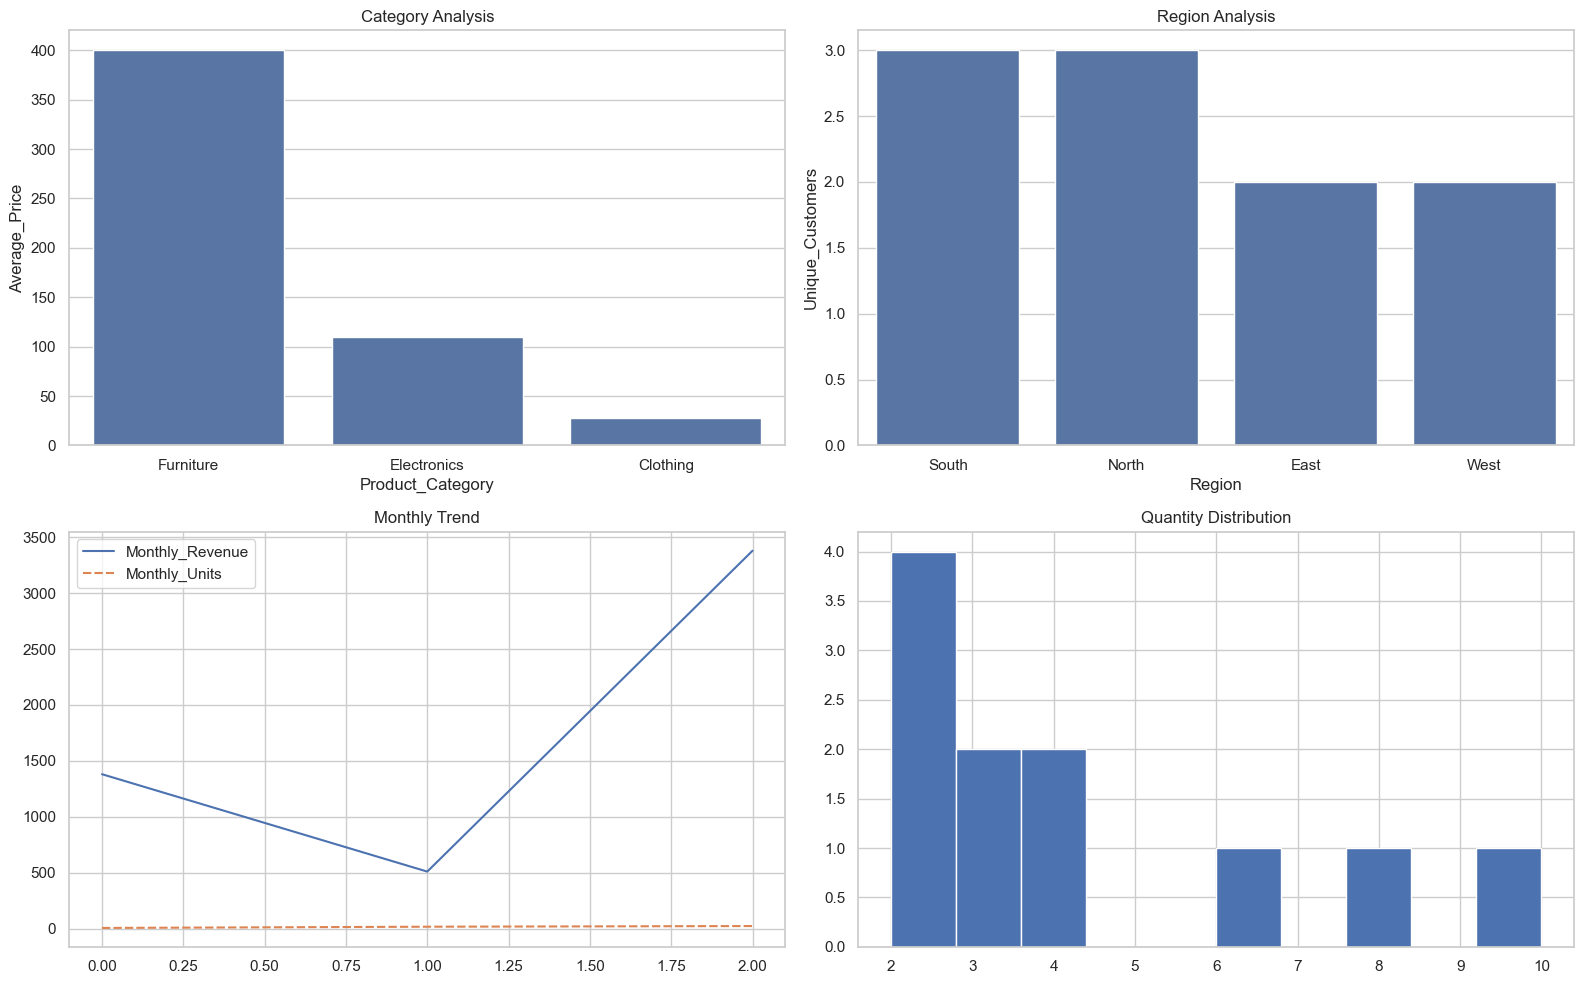

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.barplot(data=category_summary, x=category_summary.columns[0],
            y=category_summary.columns[-1], ax=axes[0, 0])
axes[0, 0].set_title("Category Analysis")

sns.barplot(data=region_summary, x=region_summary.columns[0],
            y=region_summary.columns[-1], ax=axes[0, 1])
axes[0, 1].set_title("Region Analysis")

sns.lineplot(data=monthly_summary, ax=axes[1, 0])
axes[1, 0].set_title("Monthly Trend")

axes[1, 1].hist(df["Quantity"].dropna())
axes[1, 1].set_title("Quantity Distribution")

plt.tight_layout()
plt.savefig(os.path.join(folder, "Dashboard_Poster.png"), dpi=300)
plt.show()